# 09 — Week 3 completion: LSTM / GRU, tracking, configs, rolling-origin, one benchmark table

Closes the remaining main items of Week 3 (project plan):
1. **LSTM and GRU** (direct multi-horizon networks, `src/models/rnn.py`), run from **YAML configs** with one command
   (`python src/run_experiment.py --config configs/rnn_lstm.yaml --set seed=1`), three seeds each.
2. **Scaling decision** (Meeting 1): Min-Max on train vs window-local scaling, chosen on validation with LSTM seed 0.
3. **Tracking:** every run is logged to Weights & Biases (project `datacenter-power-forecasting`, `configs/tracking.yaml`)
   and as JSON in `experiments/runs/`; notebook 07/08 results are back-filled.
4. **Alberta comparison** (LSTM): their reported numbers next to ours, with the setting differences.
5. **Rolling-origin evaluation** (`src/evaluation/rolling.py`): per-week skill of the fixed models on validation, and a
   working demo of re-fitting on an expanding window (AR model). On test it is run once, at the end of Sprint 2.
6. **One table** of all Week 3 models × horizons with mean ± sd over seeds (deterministic models: one run).

Scores are on **validation**; the test split stays closed. Runtime: each network run takes a few minutes on the Mac
(early stopping, at most 20 epochs); seven runs in total, roughly 1-2 hours on the Mac
(estimate from a 2-core test machine; the Mac is likely faster). The runs can be left running; each finished run is saved.

| Cell | Content | Needs |
|---|---|---|
| 1 | Setup, packages, helper to run a config | — |
| 2 | Tracking check (W&B online / offline) | 1 |
| 3 | Scaling decision: LSTM seed 0, minmax vs local | 1 |
| 4 | LSTM seeds 1, 2 and GRU seeds 0–2 with the chosen scaling | 3 |
| 5 | Network results: mean ± sd over seeds, parameters, time | 4 |
| 6 | Alberta comparison | 5 |
| 7 | Rolling-origin: per-week skill and expanding-window re-fit demo | 5 |
| 8 | Back-fill tracking of notebooks 07 and 08 | 2 |
| 9 | One Week 3 benchmark table (validation) | 5, 8 |
| 10 | Figures: skill of all models; learning curves | 9 |
| 11 | Summary and Week 3 completion check | 9 |

Export after saving (Cmd+S): `%run ../src/tools/nb_outputs_to_md.py 09_week3_completion.ipynb`.


In [1]:
# Cell 1: setup, packages, helper to run a config (needed by every cell)
import sys, json, time, platform, importlib, subprocess, shutil
from pathlib import Path
import numpy as np
import polars as pl
import matplotlib
import matplotlib.pyplot as plt

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src"))
missing = [m for m in ("torch", "yaml", "wandb") if importlib.util.find_spec(m) is None]
if missing:
    raise ImportError(f"missing packages: {missing}; Terminal: /opt/miniconda3/envs/dcpower/bin/python -m pip install "
                      + " ".join("pyyaml" if m == "yaml" else m for m in missing))
import torch, yaml, wandb
from evaluation import metrics as M
from evaluation import rolling as RO
from models import tabular_features as TF
from tracking import log_run, load_tracking_config

DATA = ROOT / "data" / "processed" / "model_dataset.parquet"
META = ROOT / "data" / "processed" / "model_dataset_meta.json"
OUT = ROOT / "reports" / "week3"
FIG = ROOT / "reports" / "figures" / "week3"
OUT.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
HORIZONS = (1, 5, 15)
SEEDS = (0, 1, 2)
EXTRA_OVERRIDES = []        # e.g. ["epochs=2", "max_train_samples=5000"] for a quick dry run
GROUP = "week3_rnn"

pl.Config.set_tbl_rows(100); pl.Config.set_tbl_cols(30); pl.Config.set_tbl_width_chars(240); pl.Config.set_fmt_str_lengths(200)
for p in (DATA, META, ROOT / "configs" / "rnn_lstm.yaml", ROOT / "configs" / "rnn_gru.yaml", ROOT / "configs" / "tracking.yaml",
          ROOT / "src" / "run_experiment.py", ROOT / "src" / "models" / "rnn.py", ROOT / "src" / "tracking.py",
          ROOT / "src" / "evaluation" / "rolling.py", ROOT / "reports" / "baselines" / "val_metrics.csv",
          ROOT / "reports" / "classical" / "val_metrics.csv"):
    print(f"{'OK     ' if p.exists() else 'MISSING'} {p.relative_to(ROOT)}")
print(f"python {platform.python_version()} | torch {torch.__version__} | wandb {wandb.__version__} | polars {pl.__version__}")

def run_config(config, overrides=()):
    """Run src/run_experiment.py in a subprocess and stream its output. Returns the run name."""
    ov = list(overrides) + EXTRA_OVERRIDES
    cmd = [sys.executable, "-u", str(ROOT / "src" / "run_experiment.py"), "--config", str(ROOT / "configs" / config)]
    if ov:
        cmd += ["--set", *ov]
    print("$", " ".join(cmd[1:]).replace(str(ROOT) + "/", ""))
    p = subprocess.Popen(cmd, cwd=ROOT, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    name = None
    for line in p.stdout:
        print(line, end="")
        if " run " in line and "| config" in line:
            name = line.split(" run ")[1].split(" |")[0].strip()
    p.wait()
    assert p.returncode == 0, f"run failed (exit {p.returncode}); send this output"
    return name

def load_run(name, group=GROUP):
    d = ROOT / "experiments" / group / name
    return json.loads((d / "metrics.json").read_text()), pl.read_parquet(d / "predictions_val.parquet")


OK      data/processed/model_dataset.parquet
OK      data/processed/model_dataset_meta.json
OK      configs/rnn_lstm.yaml
OK      configs/rnn_gru.yaml
OK      configs/tracking.yaml
OK      src/run_experiment.py
OK      src/models/rnn.py
OK      src/tracking.py
OK      src/evaluation/rolling.py
OK      reports/baselines/val_metrics.csv
OK      reports/classical/val_metrics.csv
python 3.11.16 | torch 2.14.1 | wandb 0.30.0 | polars 1.44.2


In [2]:
# Cell 2: tracking check: can this machine log to W&B? (needs cell 1)
tcfg = load_tracking_config(ROOT)
print("tracking config:", tcfg)
rec, used = log_run(ROOT, "tracking_check", "checks", {"purpose": "connection test"}, {"ok": 1})
print(f"W&B mode used: {used} | record {rec.relative_to(ROOT)}")
r = json.loads(rec.read_text())
if r.get("wandb_errors"):
    print("errors:", r["wandb_errors"])
if used == "offline":
    print("offline runs are stored in experiments/wandb; upload later (VPN on) with:\n"
          "  /opt/miniconda3/envs/dcpower/bin/wandb sync experiments/wandb/offline-run-*")


tracking config: {'project': 'datacenter-power-forecasting', 'entity': 'aryan-faghirollahy-uok', 'mode': 'auto'}


wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /Users/aryaneuse/.netrc.


W&B mode used: online | record experiments/runs/checks/tracking_check.json


In [3]:
# Cell 3: scaling decision with LSTM seed 0: minmax (protocol default) vs local (needs cell 1)
SCALE_RUNS = {}
for sc in ("minmax", "local"):
    SCALE_RUNS[sc] = run_config("rnn_lstm.yaml", [f"scaling={sc}", "seed=0"])
rows = []
for sc, name in SCALE_RUNS.items():
    m, _ = load_run(name)
    rows.append({"scaling": sc, **{f"val MAE h={v['h']}": round(v["MAE"], 4) for v in m["val"]},
                 "mean": round(np.mean([v["MAE"] for v in m["val"]]), 4), "best epoch": m["info"]["best_epoch"],
                 "train s": round(m["info"]["train_s"])})
SCALE_TABLE = pl.DataFrame(rows)
print(SCALE_TABLE)
SCALING = SCALE_TABLE.sort("mean")["scaling"][0]
print(f"chosen scaling (lowest mean validation MAE): {SCALING}")


$ -u src/run_experiment.py --config configs/rnn_lstm.yaml --set scaling=minmax seed=0
[12:28:33] run lstm_minmax_s0 | config /Users/aryaneuse/Desktop/Uni Project/datacenter-power-forecasting/configs/rnn_lstm.yaml | overrides ['scaling=minmax', 'seed=0']
  epoch   1 | train loss 0.00020 | val MAE 0.2852 / 0.4343 / 0.6043 kW | 54 s
  epoch   2 | train loss 0.00017 | val MAE 0.2998 / 0.4301 / 0.6077 kW | 109 s
  epoch   3 | train loss 0.00017 | val MAE 0.2893 / 0.4431 / 0.6051 kW | 164 s
  epoch   4 | train loss 0.00017 | val MAE 0.2902 / 0.4454 / 0.6128 kW | 217 s
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from /Users/aryaneuse/.netrc.
[12:32:25] done lstm_minmax_s0 | params 52,419 | train 217 s | best epoch 1 | val MAE 0.2852 / 0.4343 / 0.6043 kW | tracking: online | experiments/runs/week3_rnn/lstm_minmax_s0.json
$ -u src/run_experiment.py --config configs/rnn_lstm.yaml --set scaling=local seed=0
[12:32:26] run lstm_local_s0 | config /Users/aryaneuse/Desktop/Uni 

In [4]:
# Cell 4: remaining seeds: LSTM seeds 1, 2 and GRU seeds 0, 1, 2 with the chosen scaling (needs cell 3)
RUNS = {("lstm", 0): SCALE_RUNS[SCALING]}
for s in SEEDS[1:]:
    RUNS[("lstm", s)] = run_config("rnn_lstm.yaml", [f"scaling={SCALING}", f"seed={s}"])
for s in SEEDS:
    RUNS[("gru", s)] = run_config("rnn_gru.yaml", [f"scaling={SCALING}", f"seed={s}"])
print({f"{c}/s{s}": n for (c, s), n in RUNS.items()})


$ -u src/run_experiment.py --config configs/rnn_lstm.yaml --set scaling=local seed=1
[12:42:44] run lstm_local_s1 | config /Users/aryaneuse/Desktop/Uni Project/datacenter-power-forecasting/configs/rnn_lstm.yaml | overrides ['scaling=local', 'seed=1']
  epoch   1 | train loss 1.94424 | val MAE 0.2749 / 0.4046 / 0.5741 kW | 55 s
  epoch   2 | train loss 1.88799 | val MAE 0.2728 / 0.4044 / 0.5756 kW | 108 s
  epoch   3 | train loss 1.86482 | val MAE 0.2684 / 0.4019 / 0.5701 kW | 161 s
  epoch   4 | train loss 1.85116 | val MAE 0.2687 / 0.4005 / 0.5712 kW | 216 s
  epoch   5 | train loss 1.83319 | val MAE 0.2644 / 0.3994 / 0.5715 kW | 274 s
  epoch   6 | train loss 1.82380 | val MAE 0.2658 / 0.4045 / 0.5774 kW | 333 s
  epoch   7 | train loss 1.81448 | val MAE 0.2613 / 0.4013 / 0.5750 kW | 387 s
  epoch   8 | train loss 1.80302 | val MAE 0.2586 / 0.4005 / 0.5759 kW | 441 s
  epoch   9 | train loss 1.79800 | val MAE 0.2570 / 0.3998 / 0.5767 kW | 494 s
  epoch  10 | train loss 1.79431 | val 

In [5]:
# Cell 5: network results: mean ± sd over seeds, parameters, training and inference time (needs cell 4)
rows, RNN_PRED = [], {}
for (cell, s), name in RUNS.items():
    m, pr = load_run(name)
    RNN_PRED[(cell, s)] = pr
    for v in m["val"]:
        rows.append({"model": cell, "seed": s, "h": v["h"], "MAE": v["MAE"], "RMSE": v["RMSE"], "sMAPE": v["sMAPE"],
                     "R2": v["R2"], "R2_delta": v["R2_delta"], "skill_MAE": v["skill_MAE"], "MAE_ramp": v["MAE_ramp"],
                     "MAE_normal": v["MAE_normal"], "ramp_F1": v["ramp_F1"], "DM_p": v["DM_p"],
                     "n_params": m["info"]["n_params"], "train_s": m["info"]["train_s"],
                     "infer_ms": m["metrics"]["infer_ms_per_sample"], "best_epoch": m["info"]["best_epoch"]})
RNN = pl.DataFrame(rows)
print(RNN.group_by("model", "h").agg(pl.col("MAE").mean().round(4).alias("MAE mean"), pl.col("MAE").std().round(4).alias("MAE sd"),
      pl.col("skill_MAE").mean().round(4).alias("skill mean"), pl.col("skill_MAE").std().round(4).alias("skill sd"),
      pl.col("MAE_ramp").mean().round(4).alias("MAE ramp"), pl.col("n_params").first().alias("params"),
      pl.col("train_s").mean().round(0).alias("train s"), pl.col("infer_ms").mean().round(4).alias("infer ms/sample"),
      pl.col("best_epoch").mean().alias("best epoch")).sort("model", "h"))


shape: (6, 11)
┌───────┬─────┬──────────┬────────┬────────────┬──────────┬──────────┬────────┬─────────┬─────────────────┬────────────┐
│ model ┆ h   ┆ MAE mean ┆ MAE sd ┆ skill mean ┆ skill sd ┆ MAE ramp ┆ params ┆ train s ┆ infer ms/sample ┆ best epoch │
│ ---   ┆ --- ┆ ---      ┆ ---    ┆ ---        ┆ ---      ┆ ---      ┆ ---    ┆ ---     ┆ ---             ┆ ---        │
│ str   ┆ i64 ┆ f64      ┆ f64    ┆ f64        ┆ f64      ┆ f64      ┆ i64    ┆ f64     ┆ f64             ┆ f64        │
╞═══════╪═════╪══════════╪════════╪════════════╪══════════╪══════════╪════════╪═════════╪═════════════════╪════════════╡
│ gru   ┆ 1   ┆ 0.2583   ┆ 0.0034 ┆ 0.0987     ┆ 0.0119   ┆ 1.3133   ┆ 39363  ┆ 538.0   ┆ 0.0651          ┆ 7.333333   │
│ gru   ┆ 5   ┆ 0.4002   ┆ 0.0025 ┆ 0.0691     ┆ 0.0057   ┆ 2.1969   ┆ 39363  ┆ 538.0   ┆ 0.0651          ┆ 7.333333   │
│ gru   ┆ 15  ┆ 0.5704   ┆ 0.0036 ┆ 0.0569     ┆ 0.0059   ┆ 2.8108   ┆ 39363  ┆ 538.0   ┆ 0.0651          ┆ 7.333333   │
│ lstm  ┆ 1   ┆ 0

In [6]:
# Cell 6: Alberta comparison (LSTM). Their numbers are as reported in the paper (arXiv 2503.07756), not re-run. (needs cell 5)
lstm = RNN.filter(pl.col("model") == "lstm").group_by("h").agg(pl.col("R2").mean(), pl.col("sMAPE").mean()).sort("h")
base = pl.read_csv(ROOT / "reports" / "baselines" / "val_metrics.csv").filter(pl.col("model") == "persistence").sort("h")
rows = [{"source": "Alberta LSTM (paper)", "resolution": "1 s", "window": "300 steps (5 min)", "horizon": "90 s",
         "runs": "1", "naive baseline": "none", "R2": 0.9639, "sMAPE %": 2.26}]
for h in HORIZONS:
    l = lstm.filter(pl.col("h") == h).row(0, named=True)
    b = base.filter(pl.col("h") == h).row(0, named=True)
    rows.append({"source": f"our LSTM, h = {h} min", "resolution": "1 min", "window": "60 steps (60 min)",
                 "horizon": f"{h} min", "runs": "3 seeds", "naive baseline": "persistence", "R2": round(l["R2"], 4),
                 "sMAPE %": round(l["sMAPE"], 3)})
    rows.append({"source": f"persistence, h = {h} min", "resolution": "1 min", "window": "-", "horizon": f"{h} min",
                 "runs": "-", "naive baseline": "-", "R2": round(b["R2"], 4), "sMAPE %": round(b["sMAPE"], 3)})
ALBERTA = pl.DataFrame(rows)
print(ALBERTA)
print("Note: at 1-minute resolution persistence alone reaches R2 > 0.98, so R2 does not separate models here;")
print("the numbers are not comparable across settings (resolution, window, horizon, data period, split).")


shape: (7, 8)
┌─────────────────────────┬────────────┬───────────────────┬─────────┬─────────┬────────────────┬────────┬─────────┐
│ source                  ┆ resolution ┆ window            ┆ horizon ┆ runs    ┆ naive baseline ┆ R2     ┆ sMAPE % │
│ ---                     ┆ ---        ┆ ---               ┆ ---     ┆ ---     ┆ ---            ┆ ---    ┆ ---     │
│ str                     ┆ str        ┆ str               ┆ str     ┆ str     ┆ str            ┆ f64    ┆ f64     │
╞═════════════════════════╪════════════╪═══════════════════╪═════════╪═════════╪════════════════╪════════╪═════════╡
│ Alberta LSTM (paper)    ┆ 1 s        ┆ 300 steps (5 min) ┆ 90 s    ┆ 1       ┆ none           ┆ 0.9639 ┆ 2.26    │
│ our LSTM, h = 1 min     ┆ 1 min      ┆ 60 steps (60 min) ┆ 1 min   ┆ 3 seeds ┆ persistence    ┆ 0.997  ┆ 0.87    │
│ persistence, h = 1 min  ┆ 1 min      ┆ -                 ┆ 1 min   ┆ -       ┆ -              ┆ 0.9966 ┆ 0.916   │
│ our LSTM, h = 5 min     ┆ 1 min      ┆ 60 steps 

In [7]:
# Cell 7: rolling-origin evaluation: (a) per-week skill of fixed models on validation, (b) expanding-window re-fit demo (needs cell 5)
md = pl.read_parquet(DATA)
meta = json.loads(META.read_text())
P = md["P_kW"].fill_null(0.0).to_numpy().astype(float)
EP = md["minute_epoch"].to_numpy()
cls = pl.read_parquet(ROOT / "reports" / "classical" / "val_predictions.parquet")
bas = pl.read_parquet(ROOT / "reports" / "baselines" / "val_predictions.parquet")
best_rnn = RNN.filter(pl.col("seed") == 0).group_by("model").agg(pl.col("MAE").mean()).sort("MAE")["model"][0]
WEEK = []
for h in HORIZONS:
    srcs = {"ar_lags_cal_cov": bas.filter((pl.col("h") == h) & (pl.col("model") == "ar_lags_cal_cov")),
            "lightgbm_cov": cls.filter((pl.col("h") == h) & (pl.col("model") == "lightgbm_cov")),
            f"{best_rnn} (seed 0)": RNN_PRED[(best_rnn, 0)].filter(pl.col("h") == h)}
    for name, d in srcs.items():
        t = RO.per_block(d["minute_epoch"].to_numpy(), d["y"].to_numpy(), d["yhat"].to_numpy(), d["p0"].to_numpy(), "week")
        WEEK.append(t.with_columns(pl.lit(h).alias("h"), pl.lit(name).alias("model")))
WEEK = pl.concat(WEEK).select("h", "model", "block_start", "n", pl.col("MAE").round(4), pl.col("MAE_persistence").round(4),
                              pl.col("skill_MAE").round(4))
print("(a) skill per validation week (weeks start Monday; partial weeks with < 500 samples dropped)")
print(WEEK.pivot(on="model", index=["h", "block_start", "n"], values="skill_MAE").sort("h", "block_start"))

# (b) expanding-window re-fit demo with the ridge AR (features of ar_lags_cal_cov), weekly re-fit over validation
A = TF.arrays(md)
def ridge_fit(t, h, alpha=1000.0):
    X, _ = TF.features(A, t, "cal_cov"); y = P[t + h] - P[t]
    mu, sd = X.mean(0), X.std(0); sd[sd == 0] = 1
    Z = (X - mu) / sd
    beta = np.linalg.solve(Z.T @ Z + alpha * np.eye(Z.shape[1]), Z.T @ (y - y.mean()))
    return (mu, sd, y.mean(), beta)
def ridge_pred(mdl, t, h):
    mu, sd, ym, beta = mdl
    X, _ = TF.features(A, t, "cal_cov")
    return P[t] + ym + ((X - mu) / sd) @ beta
rows = []
for h in HORIZONS:
    ok = md[f"ok_h{h}"].to_numpy()
    sp = np.array(md[f"split_h{h}"].to_list(), dtype=object)
    orig = np.flatnonzero(ok & ((sp == "train") | (sp == "val")))
    va = np.flatnonzero(ok & (sp == "val"))
    wk = RO.block_ids(EP[va], "week")
    edges = [int(va[np.argmax(wk == k)]) for k in np.unique(wk)] + [int(va.max()) + 1]
    t_r, f_r, info = RO.rolling_refit(orig, h, edges, lambda tr: ridge_fit(tr, h), lambda m, b: ridge_pred(m, b, h))
    fixed = ridge_pred(ridge_fit(np.flatnonzero(ok & (sp == "train")), h), t_r, h)
    y = P[t_r + h]
    rows.append({"h": h, "blocks": len(info), "n": len(t_r), "MAE fixed (fit on train)": round(M.mae(y, fixed), 4),
                 "MAE weekly re-fit": round(M.mae(y, f_r), 4), "MAE persistence": round(M.mae(y, P[t_r]), 4),
                 "fit sizes": ", ".join(str(i["n_fit"]) for i in info)})
REFIT = pl.DataFrame(rows)
print("\n(b) expanding-window re-fit (AR, alpha fixed at 1000) vs the same model fitted once on train")
print(REFIT)


(a) skill per validation week (weeks start Monday; partial weeks with < 500 samples dropped)
shape: (16, 6)
┌─────┬─────────────────────┬───────┬─────────────────┬──────────────┬──────────────┐
│ h   ┆ block_start         ┆ n     ┆ ar_lags_cal_cov ┆ lightgbm_cov ┆ gru (seed 0) │
│ --- ┆ ---                 ┆ ---   ┆ ---             ┆ ---          ┆ ---          │
│ i32 ┆ datetime[μs]        ┆ i64   ┆ f64             ┆ f64          ┆ f64          │
╞═════╪═════════════════════╪═══════╪═════════════════╪══════════════╪══════════════╡
│ 1   ┆ 2021-07-26 00:00:00 ┆ 4752  ┆ 0.2288          ┆ 0.2438       ┆ 0.2134       │
│ 1   ┆ 2021-08-02 00:00:00 ┆ 10080 ┆ 0.1336          ┆ 0.1896       ┆ 0.1542       │
│ 1   ┆ 2021-08-09 00:00:00 ┆ 7080  ┆ 0.0435          ┆ 0.1454       ┆ 0.0377       │
│ 1   ┆ 2021-08-16 00:00:00 ┆ 10080 ┆ -0.1148         ┆ -0.0361      ┆ -0.048       │
│ 1   ┆ 2021-08-23 00:00:00 ┆ 10080 ┆ 0.0091          ┆ 0.0817       ┆ 0.0647       │
│ 1   ┆ 2021-08-30 00:00:00 ┆ 50

In [8]:
# Cell 8: back-fill tracking for notebooks 07 and 08 (one run per model, metrics per horizon) (needs cells 1, 2)
done = []
for src, group in (("baselines", "week3_baselines"), ("classical", "week3_classical")):
    vm = pl.read_csv(ROOT / "reports" / src / "val_metrics.csv")
    if src == "classical":   # notebook 08 repeats four notebook-07 references; log only its own models
        vm = vm.filter(~pl.col("model").is_in(pl.read_csv(ROOT / "reports" / "baselines" / "val_metrics.csv")["model"].unique().to_list()))
    for mname in vm["model"].unique(maintain_order=True).to_list():
        if (ROOT / "experiments" / "runs" / group / f"{mname}.json").exists():
            continue
        sub = vm.filter(pl.col("model") == mname)
        mets = {f"h{r['h']}/{k}": r[k] for r in sub.to_dicts() for k in ("MAE", "RMSE", "sMAPE", "R2", "R2_delta",
                                                                      "skill_MAE", "MAE_ramp", "MAE_normal", "ramp_F1")
                if k in r and r[k] is not None}
        nb_ = "07_baselines.ipynb" if src == "baselines" else "08_classical_models.ipynb"
        _, used = log_run(ROOT, mname, group, {"model": mname, "notebook": nb_, "split": "val"}, mets,
                          files=[ROOT / "reports" / src / "val_metrics.csv"])
        done.append((group, mname, used))
print(pl.DataFrame(done, schema=["group", "model", "W&B mode"], orient="row") if done else "nothing to back-fill (already logged)")


shape: (11, 3)
┌─────────────────┬───────────────────┬──────────┐
│ group           ┆ model             ┆ W&B mode │
│ ---             ┆ ---               ┆ ---      │
│ str             ┆ str               ┆ str      │
╞═════════════════╪═══════════════════╪══════════╡
│ week3_baselines ┆ persistence       ┆ online   │
│ week3_baselines ┆ pers_mod5_static  ┆ online   │
│ week3_baselines ┆ pers_mod5_rolling ┆ online   │
│ week3_baselines ┆ seasonal_naive_1d ┆ online   │
│ week3_baselines ┆ ar_lags           ┆ online   │
│ week3_baselines ┆ ar_lags_cal       ┆ online   │
│ week3_baselines ┆ ar_lags_cal_cov   ┆ online   │
│ week3_classical ┆ auto_arima        ┆ online   │
│ week3_classical ┆ auto_ets          ┆ online   │
│ week3_classical ┆ lightgbm          ┆ online   │
│ week3_classical ┆ lightgbm_cov      ┆ online   │
└─────────────────┴───────────────────┴──────────┘


In [9]:
# Cell 9: one Week 3 benchmark table on validation: model x horizon, mean ± sd over seeds (needs cells 5, 8)
FAM = {"persistence": "naive", "pers_mod5_static": "naive", "pers_mod5_rolling": "naive", "seasonal_naive_1d": "naive",
       "ar_lags": "linear", "ar_lags_cal": "linear", "ar_lags_cal_cov": "linear",
       "auto_arima": "statistical", "auto_ets": "statistical", "lightgbm": "ML", "lightgbm_cov": "ML",
       "lstm": "deep", "gru": "deep"}
COV = {"ar_lags_cal_cov", "lightgbm_cov"}
keep = ["h", "model", "MAE", "RMSE", "sMAPE", "R2", "R2_delta", "skill_MAE", "MAE_ramp", "MAE_normal", "ramp_F1", "DM_p"]
b = pl.read_csv(ROOT / "reports" / "baselines" / "val_metrics.csv").select(keep)
c = pl.read_csv(ROOT / "reports" / "classical" / "val_metrics.csv").select(keep)
c = c.filter(~pl.col("model").is_in(b["model"].unique().to_list()))
summ = json.loads((ROOT / "reports" / "classical" / "classical_summary.json").read_text())
seed_mae = {k: v for k, v in summ["seed_mae"].items()}
det = pl.concat([b, c]).with_columns(pl.lit(1).alias("n_seeds"), pl.col("MAE").alias("MAE_mean"), pl.lit(0.0).alias("MAE_sd"))
det = det.with_columns(
    pl.struct("h", "model").map_elements(lambda r: seed_mae.get(f"{r['h']}|{r['model']}", [None, None])[0] or None,
                                         return_dtype=pl.Float64).alias("_sm"),
    pl.struct("h", "model").map_elements(lambda r: seed_mae.get(f"{r['h']}|{r['model']}", [None, None])[1],
                                         return_dtype=pl.Float64).alias("_ss"))
det = det.with_columns(pl.when(pl.col("_sm").is_not_null()).then(3).otherwise(1).alias("n_seeds"),
                       pl.coalesce("_sm", "MAE_mean").alias("MAE_mean"), pl.coalesce("_ss", "MAE_sd").alias("MAE_sd")).drop("_sm", "_ss")
rnn = (RNN.group_by("model", "h").agg(pl.len().alias("n_seeds"), pl.col("MAE").mean().alias("MAE_mean"),
                                       pl.col("MAE").std().alias("MAE_sd"),
                                       *[pl.col(k).mean() for k in keep[2:] if k != "model"]))
TABLE = pl.concat([det.select(sorted(det.columns)), rnn.select(sorted(det.columns))], how="vertical_relaxed")
TABLE = TABLE.with_columns(pl.col("model").replace_strict(FAM, default="?").alias("family"),
                           pl.col("model").is_in(list(COV)).alias("covariates")).sort("h", "MAE_mean")
show = ["h", "family", "model", "covariates", "n_seeds", "MAE_mean", "MAE_sd", "RMSE", "sMAPE", "R2_delta", "skill_MAE",
        "MAE_ramp", "MAE_normal", "ramp_F1", "DM_p"]
print(TABLE.select(show).with_columns([pl.col(k).round(4) for k in show[5:]]))
TABLE.select(show).write_csv(OUT / "benchmark_val.csv")
print("\nwritten reports/week3/benchmark_val.csv")


shape: (39, 15)
┌─────┬─────────────┬───────────────────┬────────────┬─────────┬──────────┬────────┬────────┬─────────┬───────────┬───────────┬──────────┬────────────┬─────────┬────────┐
│ h   ┆ family      ┆ model             ┆ covariates ┆ n_seeds ┆ MAE_mean ┆ MAE_sd ┆ RMSE   ┆ sMAPE   ┆ R2_delta  ┆ skill_MAE ┆ MAE_ramp ┆ MAE_normal ┆ ramp_F1 ┆ DM_p   │
│ --- ┆ ---         ┆ ---               ┆ ---        ┆ ---     ┆ ---      ┆ ---    ┆ ---    ┆ ---     ┆ ---       ┆ ---       ┆ ---      ┆ ---        ┆ ---     ┆ ---    │
│ i64 ┆ str         ┆ str               ┆ bool       ┆ i64     ┆ f64      ┆ f64    ┆ f64    ┆ f64     ┆ f64       ┆ f64       ┆ f64      ┆ f64        ┆ f64     ┆ f64    │
╞═════╪═════════════╪═══════════════════╪════════════╪═════════╪══════════╪════════╪════════╪═════════╪═══════════╪═══════════╪══════════╪════════════╪═════════╪════════╡
│ 1   ┆ ML          ┆ lightgbm_cov      ┆ true       ┆ 3       ┆ 0.2464   ┆ 0.0003 ┆ 0.4615 ┆ 0.8168  ┆ 0.1845    ┆ 0.1398    ┆ 1

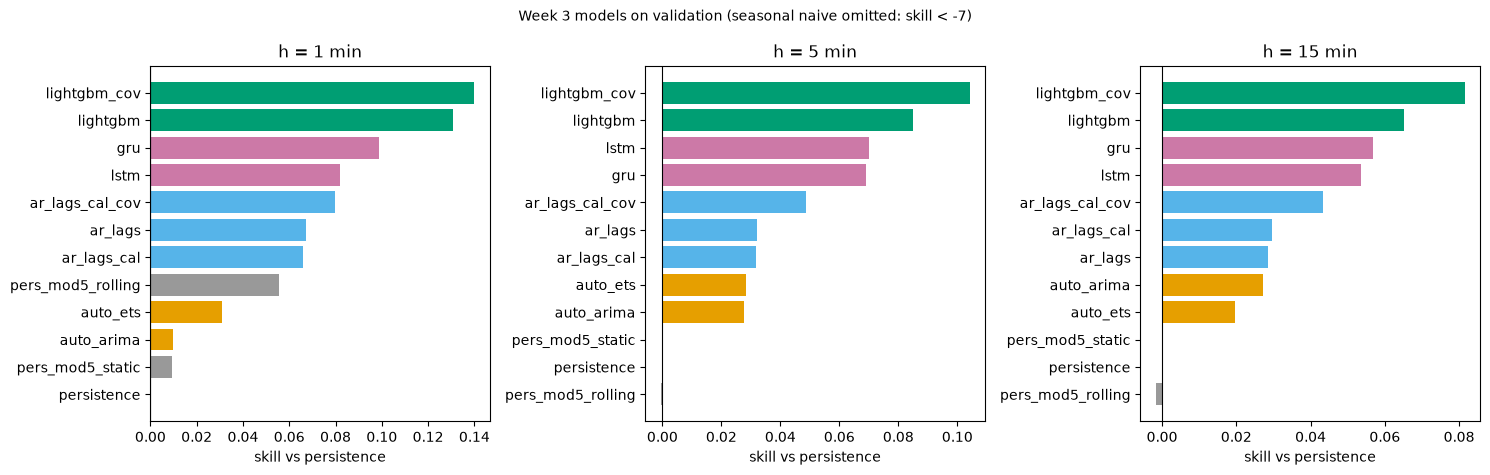

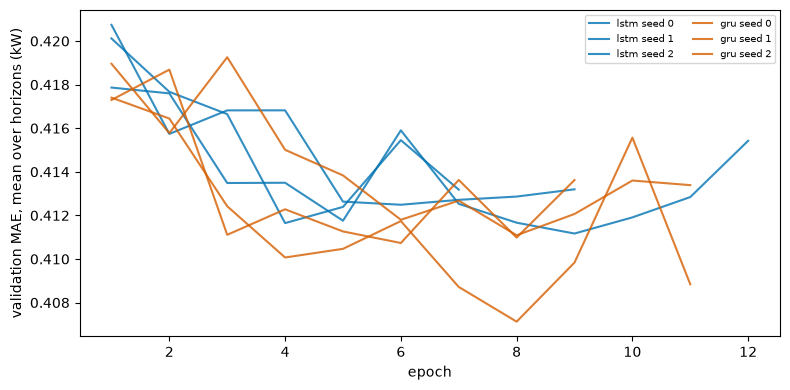

saved reports/figures/week3/01_skill_all.png and reports/figures/week3/02_learning_curves.png


In [10]:
# Cell 10: figures: skill of all models per horizon; LSTM / GRU learning curves (needs cells 4, 9)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=False)
for ax, h in zip(axes, HORIZONS):
    t = TABLE.filter((pl.col("h") == h) & (pl.col("model") != "seasonal_naive_1d")).sort("skill_MAE")
    cols = {"naive": "#999999", "linear": "#56b4e9", "statistical": "#e69f00", "ML": "#009e73", "deep": "#cc79a7"}
    ax.barh(t["model"].to_list(), t["skill_MAE"].to_list(), color=[cols.get(f, "k") for f in t["family"].to_list()])
    ax.axvline(0, color="k", lw=0.8); ax.set_title(f"h = {h} min"); ax.set_xlabel("skill vs persistence")
fig.suptitle("Week 3 models on validation (seasonal naive omitted: skill < -7)", fontsize=10)
fig.tight_layout(); fig.savefig(FIG / "01_skill_all.png", dpi=130); plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
for (cell, s), name in RUNS.items():
    hst = pl.read_csv(ROOT / "experiments" / GROUP / name / "history.csv")
    ax.plot(hst["epoch"], hst["val_MAE_mean"], color="#0072b2" if cell == "lstm" else "#d55e00", alpha=0.8,
            label=f"{cell} seed {s}")
ax.set_xlabel("epoch"); ax.set_ylabel("validation MAE, mean over horizons (kW)"); ax.legend(fontsize=7, ncol=2)
fig.tight_layout(); fig.savefig(FIG / "02_learning_curves.png", dpi=130); plt.show()
print("saved", (FIG / "01_skill_all.png").relative_to(ROOT), "and", (FIG / "02_learning_curves.png").relative_to(ROOT))


In [11]:
# Cell 11: summary, save, log the table, Week 3 completion check (needs cells 3-10)
summary = {"created": time.strftime("%Y-%m-%d %H:%M:%S"), "scaling_choice": SCALING, "scaling_table": SCALE_TABLE.to_dicts(),
           "runs": {f"{c}|{s}": n for (c, s), n in RUNS.items()}, "alberta": ALBERTA.to_dicts(),
           "refit_demo": REFIT.to_dicts(), "weekly_skill": WEEK.with_columns(pl.col("block_start").cast(pl.Utf8)).to_dicts()}
(OUT / "week3_summary.json").write_text(json.dumps(summary, indent=1, default=str))
_, used = log_run(ROOT, "week3_benchmark_table", "week3_tables", {"split": "val", "scaling_rnn": SCALING},
                  {"n_rows": TABLE.height}, files=[OUT / "benchmark_val.csv"], tables={"benchmark_val": TABLE.select(show)})
print(f"written reports/week3/week3_summary.json | table logged ({used})\n")
for h in HORIZONS:
    t = TABLE.filter(pl.col("h") == h).sort("MAE_mean")
    best = t.row(0, named=True)
    rn = {r["model"]: r for r in t.filter(pl.col("family") == "deep").to_dicts()}
    print(f"h={h:>2}: best {best['model']} MAE {best['MAE_mean']:.4f} (skill {best['skill_MAE']:+.3f}) | " +
          " | ".join(f"{m} {r['MAE_mean']:.4f} ± {r['MAE_sd']:.4f} (skill {r['skill_MAE']:+.3f})" for m, r in rn.items()))
checks = {
    "LSTM and GRU, 3 seeds each": len(RUNS) == 6,
    "all models on 3 horizons in one table": TABLE.group_by("model").len()["len"].min() == 3,
    "seeds: 3 for stochastic models (LightGBM, LSTM, GRU)": TABLE.filter(pl.col("family").is_in(["ML", "deep"]))["n_seeds"].min() == 3,
    "runs logged (JSON records)": len(list((ROOT / "experiments" / "runs").rglob("*.json"))) >= 20,
    "network runs reproducible from a YAML config": all((ROOT / "experiments" / GROUP / n / "config.yaml").exists() for n in RUNS.values()),
    "rolling-origin module works (re-fit demo)": REFIT.height == 3,
}
for k, v in checks.items():
    print(f"{'ok  ' if v else 'OPEN'} {k}")
print("WEEK 3 MAIN ITEMS COMPLETE" if all(checks.values()) else "WEEK 3 NOT COMPLETE: see OPEN items")


written reports/week3/week3_summary.json | table logged (online)

h= 1: best lightgbm_cov MAE 0.2464 (skill +0.140) | gru 0.2583 ± 0.0034 (skill +0.099) | lstm 0.2631 ± 0.0056 (skill +0.082)
h= 5: best lightgbm_cov MAE 0.3850 (skill +0.104) | lstm 0.3998 ± 0.0010 (skill +0.070) | gru 0.4002 ± 0.0025 (skill +0.069)
h=15: best lightgbm_cov MAE 0.5559 (skill +0.081) | gru 0.5704 ± 0.0036 (skill +0.057) | lstm 0.5724 ± 0.0043 (skill +0.054)
ok   LSTM and GRU, 3 seeds each
ok   all models on 3 horizons in one table
ok   seeds: 3 for stochastic models (LightGBM, LSTM, GRU)
ok   runs logged (JSON records)
ok   network runs reproducible from a YAML config
ok   rolling-origin module works (re-fit demo)
WEEK 3 MAIN ITEMS COMPLETE


In [12]:
%run ../src/tools/nb_outputs_to_md.py 09_week3_completion.ipynb

written 09_week3_completion_outputs.md | code cells 12 | figures 2 in 09_week3_completion_outputs_figures
